ARTI308 - Machine Learning

# Lab 6 Task: Ecommerce Customers
In this task, we apply what we learned in the Linear Regression lab on a new dataset: **Ecommerce Customers** (500 customers of an online clothing store). The goal is to predict `Yearly Amount Spent` using the same model used in the lab (Linear Regression).

The dataset file is in the `data` folder next to this notebook.

## 1. Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

customers = pd.read_csv("data/Ecommerce_Customers.csv")
customers.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


**Observation:** The dataset has 500 customers. Three columns are text (Email, Address, Avatar) and five are numbers. The target is Yearly Amount Spent.

## 2. Explore the data

In [2]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 69.3 KB


**Observation:** There are 500 rows and no missing values in any column. The numeric columns are float64 and the text columns are strings.

In [3]:
customers.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


**Observation:** The four features have similar scales (means of about 12 to 37 and standard deviations of about 1). The average Yearly Amount Spent is about 499 dollars (min 257, max 766). No column looks strange.

Let's check which numeric features are related to `Yearly Amount Spent`.

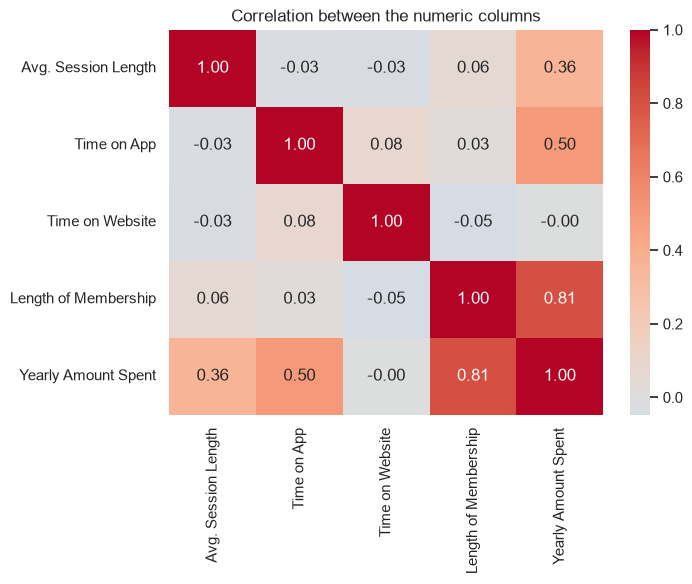

In [4]:
plt.figure(figsize=(7, 5))
sns.heatmap(customers.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between the numeric columns")
plt.show()

**Observation:** Length of Membership has the strongest relation with Yearly Amount Spent (0.81). Time on App is second (0.50), then Avg. Session Length (0.36). Time on Website is almost zero (-0.003), so it has no linear relation with spending. The features are not strongly correlated with each other, so there is no multicollinearity problem.

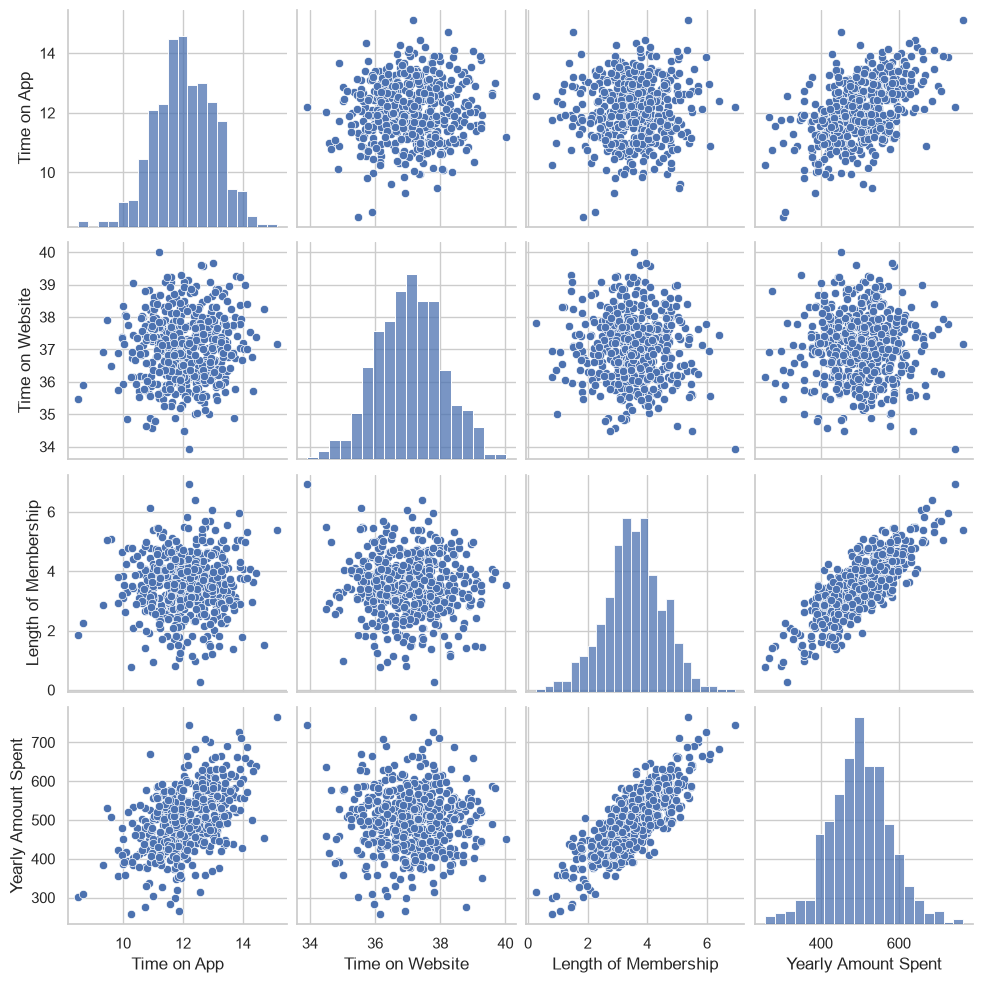

In [5]:
sns.pairplot(customers[["Time on App", "Time on Website", "Length of Membership", "Yearly Amount Spent"]])
plt.show()

**Observation:** The plot of Length of Membership against Yearly Amount Spent is a clear straight line going up. Time on App also goes up with spending, but with more spread. Time on Website shows a cloud with no pattern. All variables look roughly normal, so a linear model is a good choice.

## 3. Basic data cleaning

In [6]:
print("Missing values:", customers.isna().sum().sum())
print("Duplicate rows: ", customers.duplicated().sum())
print("Unique Avatar values:", customers["Avatar"].nunique())

Missing values: 0
Duplicate rows:  0
Unique Avatar values: 138


**Observation:** There are no missing values and no duplicate rows, so no cleaning is needed. Avatar has 138 different values, which is too many to be useful for a model.

## 4. Feature engineering
`Email`, `Address` and `Avatar` are text, so Linear Regression cannot use them directly. Two useful pieces of information can be extracted:

- **Email domain** from `Email` (`gmail`, `hotmail`, `yahoo` or `other`).
- **State** from `Address` (the two letters before the ZIP code).

Then we test if they really help.

In [7]:
customers["Email Domain"] = (customers["Email"].str.split("@").str[1]
                             .where(lambda s: s.isin(["gmail.com", "hotmail.com", "yahoo.com"]), "other"))
customers["State"] = customers["Address"].str.extract(r"([A-Z]{2})\s\d{5}(?:-\d{4})?$")[0]

print(customers["Email Domain"].value_counts())
print()
print("Different states:", customers["State"].nunique())
print("Rows without a state:", customers["State"].isna().sum())

Email Domain
other          250
hotmail.com     87
gmail.com       87
yahoo.com       76
Name: count, dtype: int64

Different states: 62
Rows without a state: 0


**Observation:** About half of the emails are from other domains, and the rest are gmail, hotmail and yahoo. The addresses give 62 different states (including territories). These are only categories, so we test them before using them.

To test the new features, we train the same Linear Regression model with and without them, using the same split.

In [8]:
num_features = ["Avg. Session Length", "Time on App", "Time on Website", "Length of Membership"]
y = customers["Yearly Amount Spent"]

def evaluate(X, name):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=101)
    model = LinearRegression().fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return {"features": name, "n_features": X.shape[1],
            "MAE": round(metrics.mean_absolute_error(y_te, pred), 2),
            "RMSE": round(np.sqrt(metrics.mean_squared_error(y_te, pred)), 2),
            "R2": round(metrics.r2_score(y_te, pred), 4)}

X_domain = pd.concat([customers[num_features],
                      pd.get_dummies(customers["Email Domain"], drop_first=True).astype(int)], axis=1)
X_state = pd.concat([customers[num_features],
                     pd.get_dummies(customers["State"].fillna("unknown"), drop_first=True).astype(int)], axis=1)

pd.DataFrame([
    evaluate(customers[num_features], "4 numeric features"),
    evaluate(X_domain, "4 numeric + Email Domain"),
    evaluate(X_state, "4 numeric + State"),
])

,features,n_features,MAE,RMSE,R2
0,4 numeric features,4,7.23,8.93,0.9890
1,4 numeric + Email Domain,7,7.22,8.93,0.9890
2,4 numeric + State,65,8.09,10.13,0.9859


**Observation:** The email domain does not change the result at all (RMSE 8.93 for both). Adding the state is worse (RMSE 10.13), because it adds 61 new columns for only 350 training rows, so the model overfits. The 4 numeric features are enough.

**Decision:** we keep only the 4 numeric features, because the new features do not improve the model.

## 5. Prepare the data for modeling
We split the data into `X` (features) and `y` (target), then into a training set (70%) and a test set (30%).

In [9]:
X = customers[num_features]
y = customers["Yearly Amount Spent"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (350, 4) | Test: (150, 4)


## 6. Train the model (Linear Regression, as in the lab)

In [10]:
lm = LinearRegression()
lm.fit(X_train, y_train)

print("Intercept:", round(lm.intercept_, 2))
coeff_df = pd.DataFrame(lm.coef_, X.columns, columns=["Coefficient"])
coeff_df.round(2)

Intercept: -1047.93


,Coefficient
Avg. Session Length,25.98
Time on App,38.59
Time on Website,0.19
Length of Membership,61.28


**Observation:** If the other features stay the same, one more year of membership adds about 61 dollars to the yearly spending. One more minute on the app adds about 39 dollars, and one more minute of session length adds about 26 dollars. Time on Website adds only 0.19 dollars, which is almost nothing. This matches the correlation results.

## 7. Evaluate the model

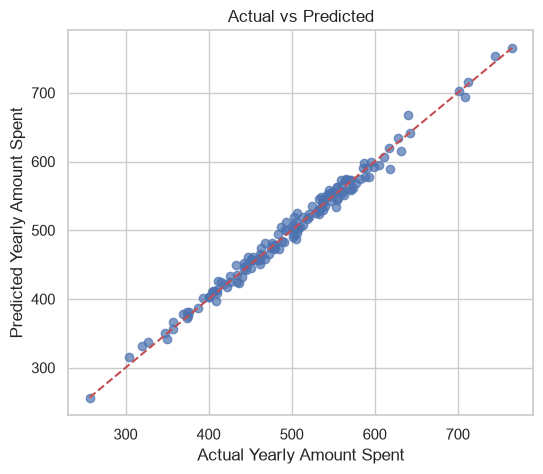

In [11]:
predictions = lm.predict(X_test)

plt.figure(figsize=(6, 5))
plt.scatter(y_test, predictions, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Yearly Amount Spent")
plt.ylabel("Predicted Yearly Amount Spent")
plt.title("Actual vs Predicted")
plt.show()

**Observation:** The points are very close to the red diagonal line, so the predictions are close to the real values. There is no curve or strange pattern.

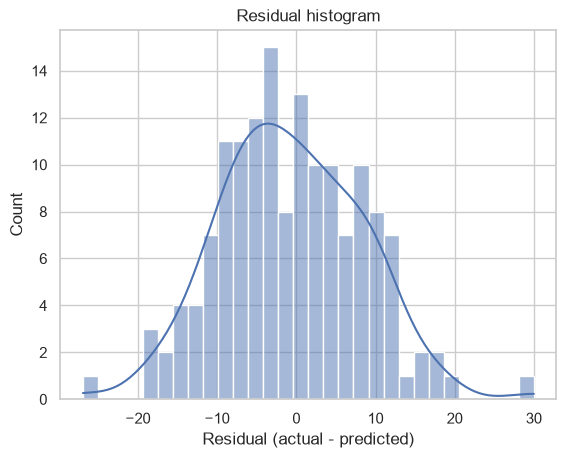

In [12]:
sns.histplot(y_test - predictions, bins=30, kde=True)
plt.xlabel("Residual (actual - predicted)")
plt.title("Residual histogram")
plt.show()

**Observation:** The residuals look like a bell shape centered near zero (mean about -0.7), with most errors between -20 and +20 dollars. This means the errors are random and the linear model is a good fit.

In [13]:
print("MAE: ", metrics.mean_absolute_error(y_test, predictions))
print("MSE: ", metrics.mean_squared_error(y_test, predictions))
print("RMSE:", np.sqrt(metrics.mean_squared_error(y_test, predictions)))
print("R2:  ", metrics.r2_score(y_test, predictions))

MAE:  7.22814865343083
MSE:  79.8130516509744
RMSE: 8.933815066978632
R2:   0.9890046246741234


**Observation:** MAE is about 7.2 dollars, so on average the prediction is wrong by about 7 dollars. RMSE is about 8.9 dollars, which is small compared to the average spending of about 499 dollars (less than 2%). R2 is 0.989, so the model explains about 98.9% of the change in Yearly Amount Spent.

### Conclusion
The Linear Regression model predicts Yearly Amount Spent very well (R2 = 0.989, RMSE = 8.93 dollars). Length of Membership is the most important feature, followed by Time on App and Avg. Session Length. Time on Website has almost no effect. For the company, this suggests focusing on the mobile app (or improving the website) and on keeping customers for longer, because these are what increase spending.